# T4: guess_pairwise_histogram returns [] instead of raising

Companion notebook to `README.md` in this folder. Running top-to-bottom regenerates every figure in `figures/` from the saved results in `data/` (or the referenced `runs/` directory).

In [1]:
# Setup: make the flat claude_files package importable and load shared helpers.
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = Path.cwd()
while not (REPO / "claude_files").exists() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO / "claude_files"))
REPORT = REPO / "reports" / "2026-10-13_t4-pairwise-histogram-no-raise"
FIG = REPORT / "figures"
DATA = REPORT / "data"
FIG.mkdir(exist_ok=True)

import evaluation as ev  # project-wide scoring convention (REL_TOL, outcome categories)


## Load results

Small tables written by `make_data.py` (in this folder) from `runs/t4_before` (clean `HEAD` = 4896568) and `runs/t4_after` (this branch), both `synthetic:n=200,seed=0`.

In [2]:
D = REPO / 'reports' / '2026-10-13_t4-pairwise-histogram-no-raise'
FIG = D / 'figures'; FIG.mkdir(exist_ok=True)
pw = pd.read_csv(D / 'data' / 'pairwise_before_after.csv')
fin = pd.read_csv(D / 'data' / 'final_before_after.csv')
BINS = ['<1d', '1-3d', '3-10d', '10-30d', '>30d']
SUCCESS = {'correct', 'diffrot'}
print('pairwise_histogram raised on', pw.error_before.notna().sum(), 'of', len(pw), 'stars before;', pw.error_after.notna().sum(), 'after')
print(pw.loc[pw.error_before.notna(), 'error_before'].value_counts())

pairwise_histogram raised on 55 of 200 stars before; 0 after
error_before
RuntimeError: guess_pairwise_histogram: fewer than 2 ACF peaks found; try lowering `prominence` or widening the lag range.    55
Name: count, dtype: int64


## Figure 1: pairwise_histogram error rate and recall by period bin

Error rate = fraction of stars where the method raised. Recall = fraction where its candidate list contains a success period (correct or diffrot). The fix should take the error rate to 0 and leave recall unchanged, because a star that raised and a star that returns `[]` both contribute no candidates.

before                   after                  
                n error_rate recall     n error_rate recall
period_bin                                                 
<1d            68      0.368  0.103    68        0.0  0.103
1-3d           45      0.356  0.467    45        0.0  0.467
3-10d          36      0.222  0.778    36        0.0  0.778
10-30d         43      0.140  0.814    43        0.0  0.814
>30d            8      0.000  1.000     8        0.0  1.000

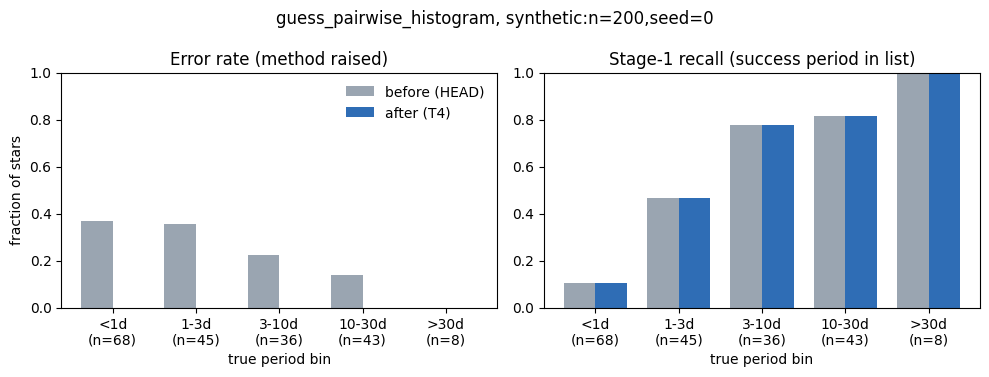

In [3]:
def by_bin(df, col_err, col_out):
    g = df.groupby('period_bin')
    return pd.DataFrame({
        'n': g.size(),
        'error_rate': g[col_err].apply(lambda s: s.notna().mean()),
        'recall': g[col_out].apply(lambda s: s.isin(SUCCESS).mean()),
    }).reindex(BINS)

tb = by_bin(pw, 'error_before', 'outcome_before'); ta = by_bin(pw, 'error_after', 'outcome_after')
summary = pd.concat({'before': tb, 'after': ta}, axis=1)
display(summary.round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharex=True)
x = np.arange(len(BINS)); w = 0.38
for ax, metric, title in [(axes[0], 'error_rate', 'Error rate (method raised)'), (axes[1], 'recall', 'Stage-1 recall (success period in list)')]:
    ax.bar(x - w/2, tb[metric], w, label='before (HEAD)', color='#9aa5b1')
    ax.bar(x + w/2, ta[metric], w, label='after (T4)', color='#2f6db5')
    ax.set_xticks(x, [f"{b}\n(n={n})" for b, n in zip(BINS, tb.n)]); ax.set_ylim(0, 1); ax.set_title(title)
    ax.set_xlabel('true period bin')
axes[0].set_ylabel('fraction of stars'); axes[0].legend(frameon=False)
fig.suptitle('guess_pairwise_histogram, synthetic:n=200,seed=0')
fig.tight_layout(); fig.savefig(FIG / 'pairwise_error_recall_by_bin.png', dpi=130); plt.show()

## Final-answer outcomes before vs after

The scorecard (and `gather_initial_guesses`) already caught the exception, so the pooled candidate list handed to `fit_rotation_period` should be identical. Check that per star.

In [4]:
print(pd.crosstab(fin.final_outcome_before, fin.final_outcome_after, rownames=['before'], colnames=['after']))
print('n_pooled identical for all stars:', (fin.n_pooled_before == fin.n_pooled_after).all())
d = (fin.final_period_after - fin.final_period_before).abs() / fin.final_period_before
print('stars with any final-period difference:', int((d > 0).sum()), '; max relative difference:', float(d.max()))
print('median per-star seconds before/after:', fin.seconds_before.median().round(2), fin.seconds_after.median().round(2))
print('median pairwise_histogram seconds before/after:', pw.seconds_before.median(), pw.seconds_after.median())

after    correct  diffrot  half  none  wrong
before                                      
correct       92        0     0     0      0
diffrot        0       42     0     0      0
half           0        0     7     0      0
none           0        0     0    48      0
wrong          0        0     0     0     11
n_pooled identical for all stars: True
stars with any final-period difference: 17 ; max relative difference: 0.00023493430979077773
median per-star seconds before/after: 11.28 11.36
median pairwise_histogram seconds before/after: 0.0033289749844698 0.0033674275036901


## Figure 2: why these stars have fewer than 2 ACF peaks

Number of ACF peaks `guess_pairwise_histogram` finds at its default adaptive prominence (5 x std of the ACF's second difference), for stars that raised vs stars that didn't, against the star's SNR. Then four example ACFs (one per period bin) of stars that raised, with the true period's multiples marked and the prominence threshold shown as a bar.

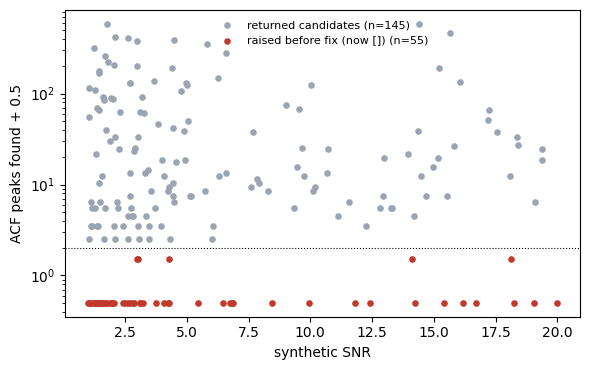

              count       mean         std  min  25%   50%   75%    max
error_before                                                           
False         145.0  65.848276  112.500391  2.0  6.0  15.0  68.0  585.0
True           55.0   0.090909    0.290129  0.0  0.0   0.0   0.0    1.0


In [5]:
fig, ax = plt.subplots(figsize=(6, 3.8))
for raised, c, lab in [(False, '#9aa5b1', 'returned candidates'), (True, '#c0392b', 'raised before fix (now [])')]:
    s = pw[pw.error_before.notna() == raised]
    ax.scatter(s.meta_snr, s.n_acf_peaks + 0.5, s=14, c=c, label=f'{lab} (n={len(s)})')
ax.set_yscale('log'); ax.set_xlabel('synthetic SNR'); ax.set_ylabel('ACF peaks found + 0.5')
ax.axhline(2, ls=':', c='k', lw=0.8); ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIG / 'n_acf_peaks_vs_snr.png', dpi=130); plt.show()
print(pw.groupby(pw.error_before.notna()).n_acf_peaks.describe())

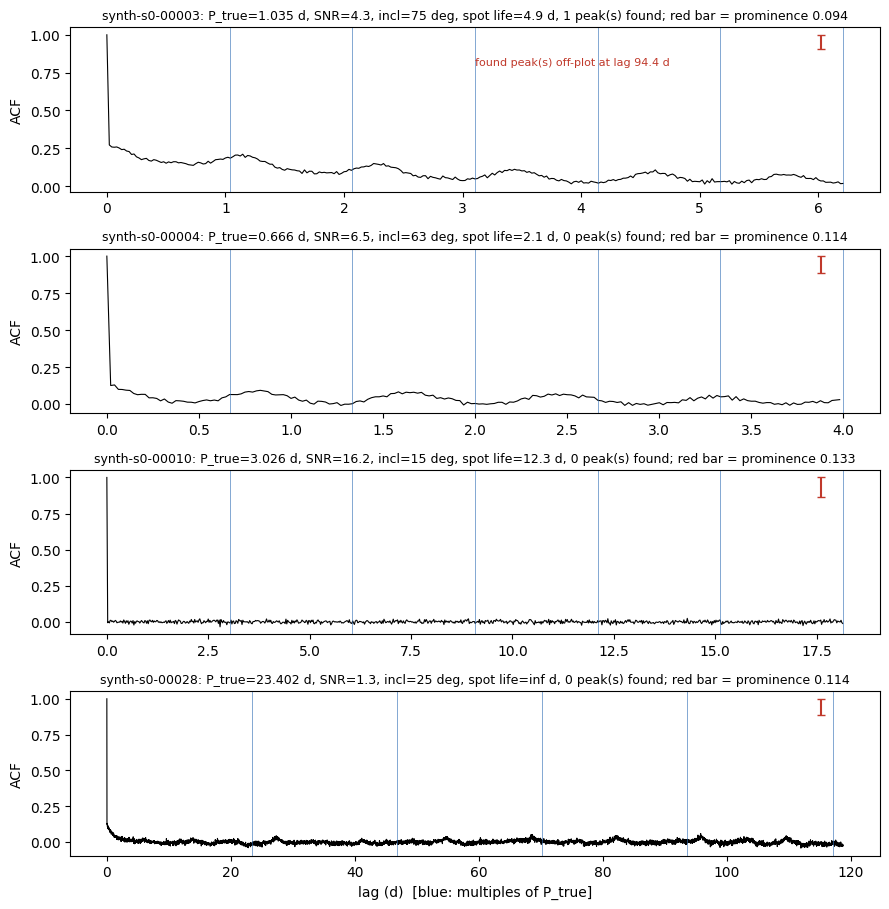

In [6]:
fin_meta = fin.set_index('star_id')
ex = np.load(D / 'data' / 'example_acfs.npz')
sids = sorted({k.split('__')[0] for k in ex.files})
fig, axes = plt.subplots(len(sids), 1, figsize=(9, 2.3 * len(sids)))
for ax, sid in zip(axes, sids):
    lags, acf, P, prom = ex[f'{sid}__lags'], ex[f'{sid}__acf'], float(ex[f'{sid}__true_period']), float(ex[f'{sid}__prominence'])
    pl = ex[f'{sid}__peak_lags']
    xmax = min(lags[-1], max(6 * P, 2))
    m = lags <= xmax
    ax.plot(lags[m], acf[m], lw=0.8, c='k')
    for k in range(1, int(xmax / P) + 1):
        ax.axvline(k * P, c='#2f6db5', lw=0.7, alpha=0.6)
    for p in pl[pl <= xmax]: ax.axvline(p, c='#c0392b', ls='--')
    off = pl[pl > xmax]
    if len(off): ax.text(0.5 * xmax, 0.8, f'found peak(s) off-plot at lag {", ".join(f"{v:.1f}" for v in off)} d', fontsize=8, color='#c0392b')
    ax.errorbar([0.97 * xmax], [acf[m].max() - prom / 2], yerr=prom / 2, c='#c0392b', capsize=3)
    row = pw.set_index('star_id').loc[sid]
    ax.set_title(f"{sid}: P_true={P:.3f} d, SNR={row.meta_snr:.1f}, incl={fin_meta.loc[sid, 'meta_inclination_deg']:.0f} deg, spot life={fin_meta.loc[sid, 'meta_spot_lifetime_days']:.1f} d, {len(pl)} peak(s) found; red bar = prominence {prom:.3f}", fontsize=9)
    ax.set_ylabel('ACF')
axes[-1].set_xlabel('lag (d)  [blue: multiples of P_true]')
fig.tight_layout(); fig.savefig(FIG / 'example_acfs_raised.png', dpi=130); plt.show()